**Disciplina:** Tópicos Especiais de Energia – Transferência de Calor utilizando PINNs (UFABC, 3º quadrimestre de 2026)
**Professores:** Prof. Dr. Daniel Jonas Dezan e Prof. MSc. Paulo de Souza Silva
**Aluno:** _preencher com o nome completo_
**Lista 2 – Condução e Solução de Blasius em Python**

Obs.: notebook desenvolvido com auxílio de ferramentas de IA, como permitido no enunciado; o código e os resultados foram executados e conferidos.

# **Exercício 5 – Camadas-limite hidrodinâmica e térmica de Blasius**

**Notebook de apoio:** `Aula05_Blasius/Aula_Blasius_v5.ipynb`

Como pede o enunciado, **não reimplementamos** RK4, shooting nem interpolação: o código do notebook de apoio foi reaproveitado, alterando apenas os parâmetros.

| Parâmetro | Notebook original | **Este exercício** |
|---|---|---|
| Posições $x$ | 0,1; 0,5; 1,0 m | **0,2; 0,6; 0,9 m** |
| Números de Prandtl | 0,6; 1,0; 7,0 | **0,3; 2; 5** |
| $U_\infty$, $\nu$ | 10 m/s; $1{,}5\times10^{-5}$ m²/s | mantidos (os do notebook) |

**Equações** (notebook de apoio):

$$
f''' + \tfrac12 f f'' = 0,\quad f(0)=f'(0)=0,\; f'(\infty)=1;
\qquad
\theta'' + \tfrac{Pr}{2} f\,\theta' = 0,\quad \theta(0)=1,\; \theta(\infty)=0;
$$

$$
\eta = y\sqrt{\frac{U_\infty}{\nu x}}, \qquad \frac{u}{U_\infty} = f'(\eta), \qquad \delta_{99}(x) = \eta_{99}\sqrt{\frac{\nu x}{U_\infty}} .
$$

In [1]:
# Bibliotecas utilizadas
import os
import numpy as np                  # funções matemáticas e vetores
import matplotlib.pyplot as plt     # gráficos

os.makedirs("figuras", exist_ok=True)   # pasta onde as figuras são salvas
plt.rcParams["figure.dpi"] = 110
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar
from scipy.interpolate import CubicSpline
import pandas as pd

# ===== PARÂMETROS ALTERADOS EM RELAÇÃO AO NOTEBOOK DE APOIO =====
x_posicoes = [0.2, 0.6, 0.9]     # [m]   (original: [0.1, 0.5, 1.0])
Pr_values = [0.3, 2.0, 5.0]      # [-]   (original: [0.6, 1.0, 7.0])
# ===== parâmetros mantidos =====
U_inf = 10.0                     # velocidade externa [m/s]
nu = 1.5e-5                      # viscosidade cinemática [m²/s]

## **Solução hidrodinâmica de Blasius** (código do notebook de apoio)

In [2]:
def blasius_ode(eta, y):
    f, df, d2f = y
    return [df, d2f, -0.5 * f * d2f]

solver_options = {"method": "RK45", "rtol": 1e-9, "atol": 1e-11}

def objective_function(guess):
    sol = solve_ivp(blasius_ode, [0, 10], [0.0, 0.0, guess], **solver_options)
    return sol.y[1][-1] - 1.0          # f'(10) - 1

best_guess = root_scalar(objective_function, bracket=[0.1, 1.0], method="brentq").root
print(f"Shooting: f''(0) = {best_guess:.5f}  (valor clássico: 0,33206)")

eta_eval = np.linspace(0, 10, 500)
sol_final = solve_ivp(blasius_ode, [0, 10], [0.0, 0.0, best_guess], t_eval=eta_eval, **solver_options)
eta, f, df, d2f = sol_final.t, sol_final.y[0], sol_final.y[1], sol_final.y[2]

Shooting: f''(0) = 0.33206  (valor clássico: 0,33206)


## **Item a)** Perfis de velocidade nas três posições, $\eta_{99}$ e $\delta_{99}$

eta_99 (u/U_inf = 0,99) = 4.910

 x [m] Re_x [-]  sqrt(nu x/U) [mm]  delta_99 [mm]
 0.200 1.33e+05              0.548          2.689
 0.600 4.00e+05              0.949          4.658
 0.900 6.00e+05              1.162          5.705


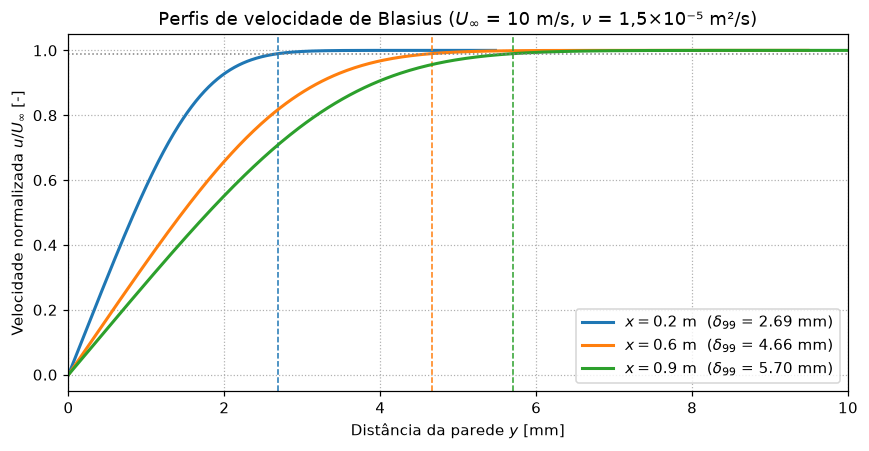

In [3]:
eta_99 = np.interp(0.99, df, eta)
print(f"eta_99 (u/U_inf = 0,99) = {eta_99:.3f}\n")

linhas = []
for x in x_posicoes:
    delta_99 = eta_99 * np.sqrt(nu * x / U_inf)
    Re_x = U_inf * x / nu
    linhas.append({"x [m]": x, "Re_x [-]": f"{Re_x:.2e}", "sqrt(nu x/U) [mm]": 1e3 * np.sqrt(nu * x / U_inf),
                   "delta_99 [mm]": 1e3 * delta_99})
print(pd.DataFrame(linhas).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

fig, ax = plt.subplots(figsize=(8, 4.2))
for x in x_posicoes:
    y = eta * np.sqrt(nu * x / U_inf)
    d99 = eta_99 * np.sqrt(nu * x / U_inf)
    linha, = ax.plot(y * 1000, df, lw=2, label=fr"$x={x:.1f}$ m  ($\delta_{{99}}$ = {d99*1000:.2f} mm)")
    ax.axvline(d99 * 1000, color=linha.get_color(), ls="--", lw=1)
ax.axhline(0.99, color="gray", ls=":", lw=1)
ax.set_xlabel(r"Distância da parede $y$ [mm]")
ax.set_ylabel(r"Velocidade normalizada $u/U_\infty$ [-]")
ax.set_title(r"Perfis de velocidade de Blasius ($U_\infty$ = 10 m/s, $\nu$ = 1,5×10⁻⁵ m²/s)")
ax.set_xlim(0, 10)
ax.grid(True, linestyle=":")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/ex5a_perfis_velocidade.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretação.** Em variáveis de similaridade o perfil $f'(\eta)$ é **o mesmo** em todas as posições. O que muda é a escala física $\sqrt{\nu x/U_\infty}$, de modo que a camada-limite fica mais espessa à medida que o escoamento avança: $\delta_{99} \propto \sqrt{x}$.

O valor obtido, $\eta_{99} \approx 4{,}91$, é o clássico ($\delta_{99} \approx 4{,}91\,x/\sqrt{Re_x}$). Ele dá $\delta_{99} \approx 2{,}69$ mm em $x=0{,}2$ m, $4{,}66$ mm em $x=0{,}6$ m e $5{,}70$ mm em $x=0{,}9$ m. Triplicar $x$ (de 0,2 para 0,6 m) multiplica a espessura por $\sqrt3 \approx 1{,}73$. Ao mesmo tempo, o perfil fica menos inclinado junto à parede, e a tensão de cisalhamento $\tau_w \propto f''(0)/\sqrt{x}$ diminui ao longo da placa.

> **Observação:** em $x = 0{,}9$ m, $Re_x = 6\times10^5$, acima do valor crítico usual de transição ($\approx 5\times10^5$). Nessa posição, a solução laminar de Blasius é uma idealização; numa placa real o escoamento poderia já estar em transição para turbulento.

## **Item b)** Perfis térmicos $\theta(\eta)$ para $Pr = 0{,}3$, $2$ e $5$

    Pr  theta'(0) [-]  -0,332 Pr^(1/3) (correlação)  eta_T (theta=0,01)  eta_T / eta_99  Pr^(-1/3)
0.3000        -0.2149                       -0.2223              7.8673          1.6023     1.4938
2.0000        -0.4223                       -0.4183              3.7996          0.7739     0.7937
5.0000        -0.5767                       -0.5677              2.7504          0.5602     0.5848


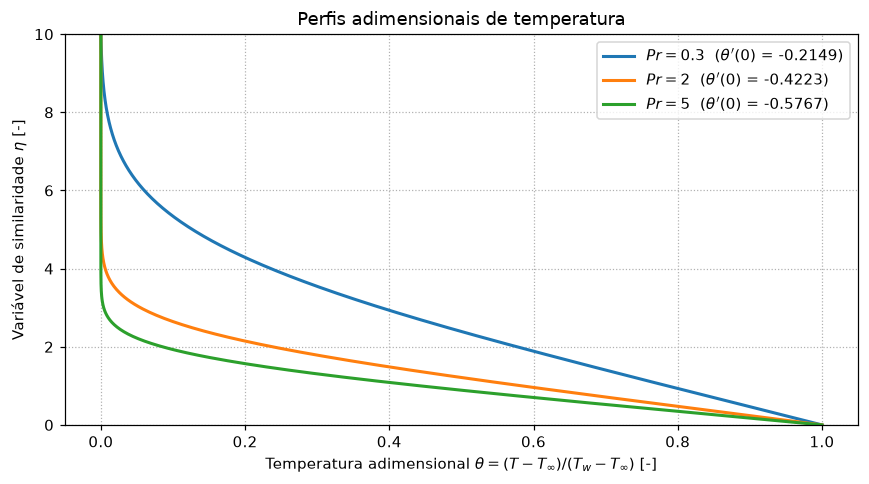

In [4]:
# Código do notebook de apoio: interpolação de f(eta) + shooting térmico
f_interp = CubicSpline(eta, f)

def thermal_ode(eta_local, y, Pr):
    theta, dtheta = y
    return [dtheta, -0.5 * Pr * f_interp(eta_local) * dtheta]

def thermal_residual(slope, Pr):
    sol = solve_ivp(thermal_ode, [0, 10], [1.0, slope], args=(Pr,))
    return sol.y[0, -1]                       # theta(10), que deve ser ~0

def solve_thermal_profile(Pr):
    root = root_scalar(lambda s: thermal_residual(s, Pr), bracket=[-2.0, -0.01], method="brentq")
    sol = solve_ivp(thermal_ode, [0, 10], [1.0, root.root], t_eval=eta, args=(Pr,))
    return root.root, sol.y[0]

thermal_profiles, thermal_slopes, eta_T_99 = {}, {}, {}
for Pr in Pr_values:
    thermal_slopes[Pr], thermal_profiles[Pr] = solve_thermal_profile(Pr)
    eta_T_99[Pr] = np.interp(0.01, thermal_profiles[Pr][::-1], eta[::-1])   # theta = 0,01

tabela_b = pd.DataFrame({
    "Pr": Pr_values,
    "theta'(0) [-]": [thermal_slopes[p] for p in Pr_values],
    "-0,332 Pr^(1/3) (correlação)": [-0.332 * p ** (1 / 3) for p in Pr_values],
    "eta_T (theta=0,01)": [eta_T_99[p] for p in Pr_values],
    "eta_T / eta_99": [eta_T_99[p] / eta_99 for p in Pr_values],
    "Pr^(-1/3)": [p ** (-1 / 3) for p in Pr_values],
})
print(tabela_b.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, ax = plt.subplots(figsize=(8, 4.5))
for Pr in Pr_values:
    ax.plot(thermal_profiles[Pr], eta, lw=2,
            label=fr"$Pr={Pr:g}$  ($\theta'(0)$ = {thermal_slopes[Pr]:.4f})")
ax.set_xlabel(r"Temperatura adimensional $\theta = (T-T_\infty)/(T_w-T_\infty)$ [-]")
ax.set_ylabel(r"Variável de similaridade $\eta$ [-]")
ax.set_ylim(0, 10)
ax.set_title("Perfis adimensionais de temperatura")
ax.grid(True, linestyle=":")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/ex5b_perfis_termicos.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretação.** $Pr = \nu/\alpha$ compara a difusão de quantidade de movimento com a difusão de calor.

- **$Pr = 0{,}3$** ($\alpha > \nu$): o calor se difunde mais rápido que a quantidade de movimento, então a temperatura "sente" a parede mais longe. A camada térmica é a **mais espessa** ($\eta_T \approx 7{,}9$) e o gradiente na parede é o menor ($\theta'(0) \approx -0{,}215$).
- **$Pr = 5$** ($\alpha < \nu$): o calor fica confinado perto da parede. A camada térmica é a **mais fina** ($\eta_T \approx 2{,}75$) e o gradiente na parede é o maior ($\theta'(0) \approx -0{,}577$), o que significa maior fluxo de calor, pois $Nu_x = -\theta'(0)\,Re_x^{1/2}$.
- **$Pr = 2$** fica no meio ($\theta'(0) \approx -0{,}422$).

Os valores de $\theta'(0)$ concordam com a correlação de Pohlhausen, $-0{,}332\,Pr^{1/3}$, dentro de cerca de 3%. A maior diferença é em $Pr=0{,}3$, onde essa correlação, deduzida para $Pr \gtrsim 0{,}6$, é menos precisa.

## **Item c)** Comparação $f'(\eta)$ × $\theta(\eta)$ e espessuras ao longo da placa

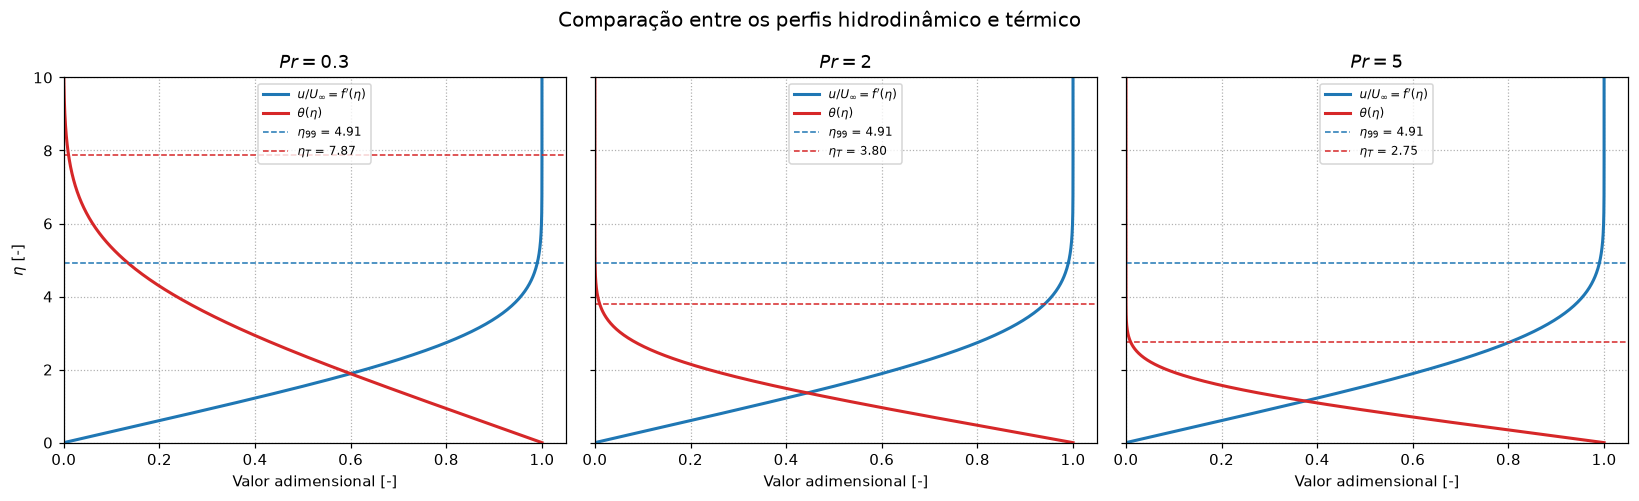

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, Pr in zip(axes, Pr_values):
    ax.plot(df, eta, color="tab:blue", lw=2, label=r"$u/U_\infty = f'(\eta)$")
    ax.plot(thermal_profiles[Pr], eta, color="tab:red", lw=2, label=r"$\theta(\eta)$")
    ax.axhline(eta_99, color="tab:blue", ls="--", lw=1, label=fr"$\eta_{{99}}$ = {eta_99:.2f}")
    ax.axhline(eta_T_99[Pr], color="tab:red", ls="--", lw=1, label=fr"$\eta_T$ = {eta_T_99[Pr]:.2f}")
    ax.set_title(fr"$Pr = {Pr:g}$")
    ax.set_xlabel("Valor adimensional [-]")
    ax.grid(True, linestyle=":")
    ax.legend(fontsize=8, loc="upper center")
axes[0].set_ylabel(r"$\eta$ [-]")
axes[0].set_xlim(0, 1.05)
axes[0].set_ylim(0, 10)
fig.suptitle("Comparação entre os perfis hidrodinâmico e térmico", fontsize=13)
plt.tight_layout()
plt.savefig("figuras/ex5c_fprime_vs_theta.png", dpi=300, bbox_inches="tight")
plt.show()

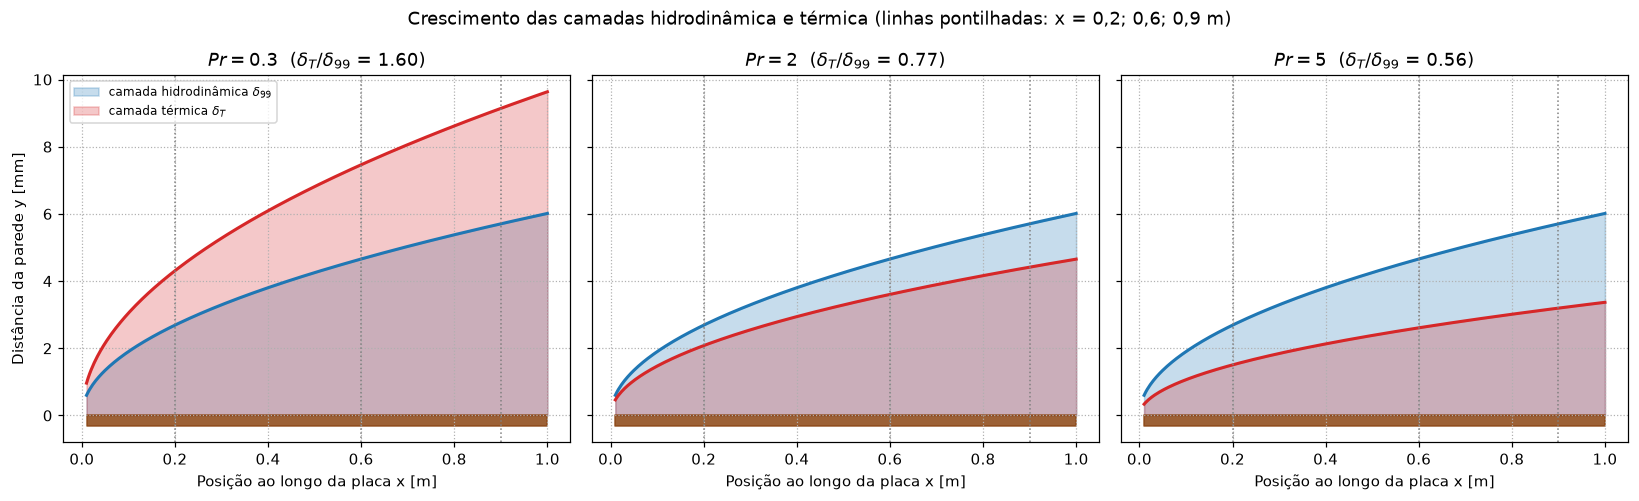

 x [m]  delta_99 [mm]  delta_T Pr=0.3 [mm]  delta_T Pr=2 [mm]  delta_T Pr=5 [mm]
 0.200          2.689                4.309              2.081              1.506
 0.600          4.658                7.464              3.605              2.609
 0.900          5.705                9.141              4.415              3.196


In [6]:
x_plot = np.linspace(0.01, 1.0, 300)
delta_h = eta_99 * np.sqrt(nu * x_plot / U_inf)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, Pr in zip(axes, Pr_values):
    delta_T = eta_T_99[Pr] * np.sqrt(nu * x_plot / U_inf)
    ax.fill_between(x_plot, 0, delta_h * 1000, color="tab:blue", alpha=0.25, label=r"camada hidrodinâmica $\delta_{99}$")
    ax.fill_between(x_plot, 0, delta_T * 1000, color="tab:red", alpha=0.25, label=r"camada térmica $\delta_T$")
    ax.plot(x_plot, delta_h * 1000, color="tab:blue", lw=2)
    ax.plot(x_plot, delta_T * 1000, color="tab:red", lw=2)
    for xp in x_posicoes:
        ax.axvline(xp, color="gray", ls=":", lw=1)
    ax.fill_between(x_plot, -0.3, 0, color="saddlebrown", alpha=0.85)
    ax.set_title(fr"$Pr = {Pr:g}$  ($\delta_T/\delta_{{99}}$ = {eta_T_99[Pr]/eta_99:.2f})")
    ax.set_xlabel("Posição ao longo da placa x [m]")
    ax.grid(True, linestyle=":")
axes[0].set_ylabel("Distância da parede y [mm]")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Crescimento das camadas hidrodinâmica e térmica (linhas pontilhadas: x = 0,2; 0,6; 0,9 m)", fontsize=12)
plt.tight_layout()
plt.savefig("figuras/ex5c_espessuras_ao_longo_da_placa.png", dpi=300, bbox_inches="tight")
plt.show()

linhas = []
for x in x_posicoes:
    linha = {"x [m]": x, "delta_99 [mm]": 1e3 * eta_99 * np.sqrt(nu * x / U_inf)}
    for Pr in Pr_values:
        linha[f"delta_T Pr={Pr:g} [mm]"] = 1e3 * eta_T_99[Pr] * np.sqrt(nu * x / U_inf)
    linhas.append(linha)
print(pd.DataFrame(linhas).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

**Discussão.** As duas camadas crescem com $\sqrt{x}$, logo a razão $\delta_T/\delta_{99}$ é **constante ao longo da placa** e depende só de $Pr$, aproximadamente como $Pr^{-1/3}$:

- **$Pr = 0{,}3 < 1$:** $\delta_T/\delta_{99} \approx 1{,}60$. A camada térmica **envolve** a hidrodinâmica; há aquecimento do fluido numa região onde a velocidade já é praticamente $U_\infty$.
- **$Pr = 2$:** $\delta_T/\delta_{99} \approx 0{,}77$. A camada térmica já fica **dentro** da hidrodinâmica.
- **$Pr = 5$:** $\delta_T/\delta_{99} \approx 0{,}56$. A camada térmica é bem mais fina e fica imersa na região de baixa velocidade junto à parede.

Para $Pr = 1$ as duas espessuras seriam praticamente iguais, porque as equações de $f'$ e $\theta$ teriam a mesma forma. É o caso intermediário entre $0{,}3$ e $2$.

## **Item d)** Comparação com o HTML interativo

Abrimos o arquivo `Aula05_Blasius/Aula_Blasius_Interativo.html` do repositório da disciplina e reproduzimos a configuração **$x = 0{,}6$ m e $Pr = 2$**:

<img src="figuras/ex5d_html_x0.6_Pr2.jpg" width="650">

Os valores exibidos pelo HTML para as três posições e os três Prandtl (lidos diretamente da página) foram anotados na tabela abaixo e comparados com os calculados neste notebook:

In [7]:
# Valores lidos do HTML interativo (x e Pr ajustados nos controles da página)
html = {  # (x, Pr): (delta_h99 [mm], theta'(0), delta_T99 [mm])
    (0.2, 0.3): (2.689, -0.21494, 4.308), (0.2, 2.0): (2.689, -0.42231, 2.081), (0.2, 5.0): (2.689, -0.57669, 1.506),
    (0.6, 0.3): (4.658, -0.21494, 7.462), (0.6, 2.0): (4.658, -0.42231, 3.604), (0.6, 5.0): (4.658, -0.57669, 2.609),
    (0.9, 0.3): (5.705, -0.21494, 9.139), (0.9, 2.0): (5.705, -0.42231, 4.414), (0.9, 5.0): (5.705, -0.57669, 3.195),
}
linhas = []
for (x, Pr), (dh_html, dth_html, dT_html) in html.items():
    escala = np.sqrt(nu * x / U_inf) * 1e3
    linhas.append({"x [m]": x, "Pr": Pr,
                   "δ99 notebook": eta_99 * escala, "δ99 HTML": dh_html,
                   "θ'(0) notebook": thermal_slopes[Pr], "θ'(0) HTML": dth_html,
                   "δT notebook": eta_T_99[Pr] * escala, "δT HTML": dT_html})
comp = pd.DataFrame(linhas)
print("Espessuras em mm:\n")
print(comp.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
for nome, unidade in [("δ99", " mm"), ("θ'(0)", ""), ("δT", " mm")]:
    diferenca = np.max(np.abs(comp[nome + " notebook"] - comp[nome + " HTML"]))
    print(f"Maior diferença em {nome}: {diferenca:.5f}{unidade}")

Espessuras em mm:

 x [m]     Pr  δ99 notebook  δ99 HTML  θ'(0) notebook  θ'(0) HTML  δT notebook  δT HTML
0.2000 0.3000        2.6893    2.6890         -0.2149     -0.2149       4.3091   4.3080
0.2000 2.0000        2.6893    2.6890         -0.4223     -0.4223       2.0811   2.0810
0.2000 5.0000        2.6893    2.6890         -0.5767     -0.5767       1.5065   1.5060
0.6000 0.3000        4.6580    4.6580         -0.2149     -0.2149       7.4635   7.4620
0.6000 2.0000        4.6580    4.6580         -0.4223     -0.4223       3.6046   3.6040
0.6000 5.0000        4.6580    4.6580         -0.5767     -0.5767       2.6093   2.6090
0.9000 0.3000        5.7049    5.7050         -0.2149     -0.2149       9.1409   9.1390
0.9000 2.0000        5.7049    5.7050         -0.4223     -0.4223       4.4148   4.4140
0.9000 5.0000        5.7049    5.7050         -0.5767     -0.5767       3.1957   3.1950
Maior diferença em δ99: 0.00031 mm
Maior diferença em θ'(0): 0.00002
Maior diferença em δT: 0.00194 m

**Comentário.** Os resultados são **compatíveis**. Para $x = 0{,}6$ m e $Pr = 2$, o HTML mostra $\delta_{h,99} = 4{,}658$ mm, $\theta'(0) = -0{,}42231$ e $\delta_{T,99} = 3{,}604$ mm, os mesmos valores do notebook dentro do arredondamento da página. O mesmo vale para as outras oito combinações da tabela.

Qualitativamente, as tendências também coincidem:

- ao aumentar $x$ no controle, o perfil de velocidade mantém a forma e só "estica" em $y$;
- ao aumentar $Pr$, o perfil térmico fica mais íngreme e a camada térmica mais fina;
- no gráfico conjunto, com $Pr = 2$, a curva de $\theta$ chega a zero antes de $u/U_\infty$ chegar a 1.

O HTML usa os mesmos $U_\infty$ e $\nu$ do notebook. Segundo o próprio texto da página, o perfil térmico é interpolado entre soluções pré-calculadas, o que explica diferenças apenas na última casa decimal.

## **Síntese: efeito de $x$ e $Pr$**

- **$x$** muda apenas a **escala** das camadas ($\delta \propto \sqrt{x}$); os perfis adimensionais não mudam.
- **$Pr$** muda a **forma** do perfil térmico e a razão $\delta_T/\delta \approx Pr^{-1/3}$. Fluidos com $Pr$ baixo (gases leves, metais líquidos) têm camadas térmicas espessas e menor gradiente na parede; fluidos com $Pr$ alto (água, óleos) têm camadas finas e maior fluxo de calor.